In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import time

from selenium import webdriver
from selenium.webdriver.chrome.options import Options


# Browser setup

options = Options()
options.add_argument("--start-maximized")
options.add_argument("--incognito")
options.add_argument("--disable-notifications")
options.add_argument("--disable-blink-features=AutomationControlled")

driver = webdriver.Chrome(options=options)


# Lists

tv_names = []
original_prices = []
discount_prices = []
discount = []
brand_list = []
inches = []
product_urls = []


# Scrape 10 pages

for page in range(1, 11):

    if page == 1:
        url = "https://www.poorvika.com/televisions/s"
    else:
        url = f"https://www.poorvika.com/televisions/s?page={page}"

    print(f"Scraping Page {page}/10...")

    driver.get(url)
    time.sleep(3)

    html = driver.page_source
    soup = BeautifulSoup(html, "html.parser")

    product_links = soup.find_all("a", href=True)

    for link in product_links:

        name = link.get_text(" ", strip=True)

        # Only TV products
        if "inch" not in name.lower():
            continue

        # Need prices
        prices = re.findall(r"₹\s*[\d,]+", name)

        if len(prices) < 2:
            continue

        
        # Product name
        
        tv_name = re.split(r"\(\s*\d+\s*inch", name, flags=re.I)[0].strip()

       
        # Prices
       
        discount_price = prices[0]
        original_price = prices[1]

        original_value = float(
            original_price.replace("₹", "").replace(",", "").strip()
        )

        discount_value = float(
            discount_price.replace("₹", "").replace(",", "").strip()
        )

      
        # Discount %
       
        discount_percent = round(
            ((original_value - discount_value) / original_value) * 100
        )

        discount_percent = str(discount_percent) + "%"

     
        # Inches
      
        inch_match = re.search(
            r"\(\s*(\d+)\s*inch",
            name,
            re.I
        )

        if inch_match:
            inch = int(inch_match.group(1))
        else:
            continue

        
        # Brand
      
        brand = tv_name.split()[0]

       
        # Product URL
       
        product_url = link.get("href")

        if product_url.startswith("/"):
            product_url = "https://www.poorvika.com" + product_url

    
        # Store data
    
        tv_names.append(tv_name)
        original_prices.append(original_price)
        discount_prices.append(discount_price)
        discount.append(discount_percent)
        brand_list.append(brand)
        inches.append(inch)
        product_urls.append(product_url)

# DataFrame

df = pd.DataFrame({
    "TV Name": tv_names,
    "Original Price": original_prices,
    "Discount Price": discount_prices,
    "Discount %": discount,
    "Brand": brand_list,
    "Inches": inches,
    "Product URL": product_urls
})

print("Total TV records:", len(df))

df

Scraping Page 1/10...
Scraping Page 2/10...
Scraping Page 3/10...
Scraping Page 4/10...
Scraping Page 5/10...
Scraping Page 6/10...
Scraping Page 7/10...
Scraping Page 8/10...
Scraping Page 9/10...
Scraping Page 10/10...
Total TV records: 396


,TV Name,Original Price,Discount Price,Discount %,Brand,Inches,Product URL
0,"Samsung 4K Ultra HD Neo QLED Smart TV QN80H, Q...","₹ 2,19,900","₹ 1,92,990",12%,Samsung,75,https://www.poorvika.com/samsung-4k-ultra-hd-n...
1,"Haier 4K Ultra HD Mini LED AI Smart Google TV,...","₹ 89,990","₹ 58,490",35%,Haier,55,https://www.poorvika.com/haier-4k-ultra-hd-min...
2,"LG Full HD Smart LED TV LB65 2026, 43LB6500PLB","₹ 37,990","₹ 29,990",21%,LG,43,https://www.poorvika.com/lg-full-hd-smart-led-...
3,Samsung 4K Ultra HD Micro RGB Smart TV 2026 R8...,"₹ 7,49,900","₹ 5,89,990",21%,Samsung,100,https://www.poorvika.com/samsung-4k-ultra-hd-m...
4,"Samsung Crystal 4K Ultra HD LED Smart TV 2026,...","₹ 5,19,900","₹ 4,32,990",17%,Samsung,98,https://www.poorvika.com/samsung-crystal-4k-ul...
...,...,...,...,...,...,...,...
391,TCL HD Ready LED Smart TV S65A,"₹ 29,990","₹ 16,990",43%,TCL,32,https://www.poorvika.com/tcl-hd-ready-led-smar...
392,Redmi HD Ready Smart TV,"₹ 24,999","₹ 13,999",44%,Redmi,32,https://www.poorvika.com/redmi-hd-ready-smart-...
393,Redmi 4K Ultra HD X Series Smart LED TV,"₹ 44,999","₹ 29,400",35%,Redmi,50,https://www.poorvika.com/redmi-4k-ultra-hd-x-s...
394,Mi 4K Ultra HD Tv 5X,"₹ 49,999","₹ 31,999",36%,Mi,43,https://www.poorvika.com/mi-4k-ultra-hd-tv-5x-...


In [3]:
df.head()

,TV Name,Original Price,Discount Price,Discount %,Brand,Inches,Product URL
0,"Samsung 4K Ultra HD Neo QLED Smart TV QN80H, Q...","₹ 2,19,900","₹ 1,92,990",12%,Samsung,75,https://www.poorvika.com/samsung-4k-ultra-hd-n...
1,"Haier 4K Ultra HD Mini LED AI Smart Google TV,...","₹ 89,990","₹ 58,490",35%,Haier,55,https://www.poorvika.com/haier-4k-ultra-hd-min...
2,"LG Full HD Smart LED TV LB65 2026, 43LB6500PLB","₹ 37,990","₹ 29,990",21%,LG,43,https://www.poorvika.com/lg-full-hd-smart-led-...
3,Samsung 4K Ultra HD Micro RGB Smart TV 2026 R8...,"₹ 7,49,900","₹ 5,89,990",21%,Samsung,100,https://www.poorvika.com/samsung-4k-ultra-hd-m...
4,"Samsung Crystal 4K Ultra HD LED Smart TV 2026,...","₹ 5,19,900","₹ 4,32,990",17%,Samsung,98,https://www.poorvika.com/samsung-crystal-4k-ul...


In [4]:
df.shape

(396, 7)

In [5]:
df.columns

Index(['TV Name', 'Original Price', 'Discount Price', 'Discount %', 'Brand',
       'Inches', 'Product URL'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 396 entries, 0 to 395
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   TV Name         396 non-null    object
 1   Original Price  396 non-null    object
 2   Discount Price  396 non-null    object
 3   Discount %      396 non-null    object
 4   Brand           396 non-null    object
 5   Inches          396 non-null    int64 
 6   Product URL     396 non-null    object
dtypes: int64(1), object(6)
memory usage: 21.8+ KB


In [7]:
df.isnull().sum()

TV Name           0
Original Price    0
Discount Price    0
Discount %        0
Brand             0
Inches            0
Product URL       0
dtype: int64

In [11]:
df["Original Price"] = df["Original Price"].str.replace("₹", "").str.replace(",", "").astype(float)

df["Discount Price"] = df["Discount Price"].str.replace("₹", "").str.replace(",", "").astype(float)

df["Discount %"] = df["Discount %"].str.replace("%", "").astype(float)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 396 entries, 0 to 395
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TV Name         396 non-null    object 
 1   Original Price  396 non-null    float64
 2   Discount Price  396 non-null    float64
 3   Discount %      396 non-null    float64
 4   Brand           396 non-null    object 
 5   Inches          396 non-null    int64  
 6   Product URL     396 non-null    object 
dtypes: float64(3), int64(1), object(3)
memory usage: 21.8+ KB


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
pd.set_option("display.float_format", "{:.2f}".format)

df.describe()

,Original Price,Discount Price,Discount %,Inches
count,396.00,396.00,396.00,396.00
mean,173114.56,99829.80,39.45,56.86
std,188315.56,103608.72,13.24,15.76
min,12999.00,4990.00,3.00,24.00
25%,54974.25,34078.50,31.00,43.00
50%,107400.00,62745.00,39.00,55.00
75%,223400.00,130092.50,49.00,65.00
max,1336600.00,692590.00,76.00,100.00


In [12]:
df[["Original Price", "Discount Price", "Discount %", "Inches"]].describe()

,Original Price,Discount Price,Discount %,Inches
count,396.00,396.00,396.00,396.00
mean,173114.56,99829.80,39.45,56.86
std,188315.56,103608.72,13.24,15.76
min,12999.00,4990.00,3.00,24.00
25%,54974.25,34078.50,31.00,43.00
50%,107400.00,62745.00,39.00,55.00
75%,223400.00,130092.50,49.00,65.00
max,1336600.00,692590.00,76.00,100.00


### Brand Analysis

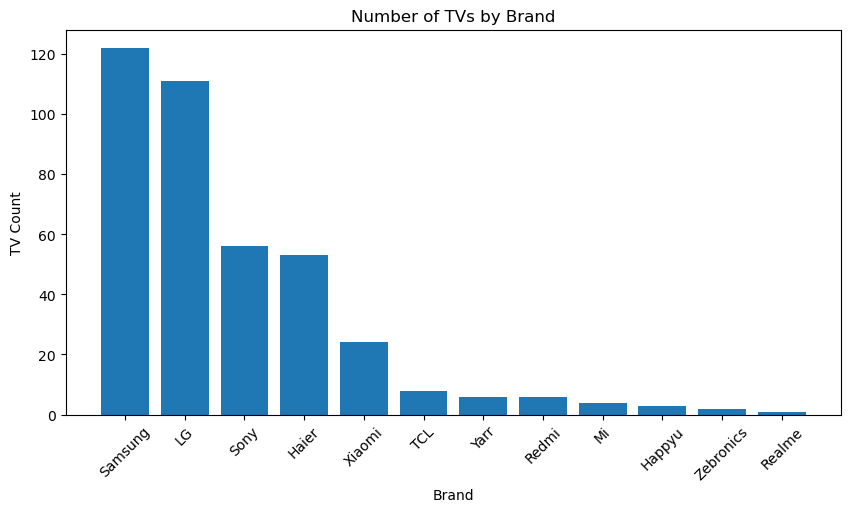

In [13]:
# Which brands have the most TV models?
import matplotlib.pyplot as plt

brand_count = df["Brand"].value_counts()

plt.figure(figsize=(10,5))
plt.bar(brand_count.index, brand_count.values)
plt.title("Number of TVs by Brand")
plt.xlabel("Brand")
plt.ylabel("TV Count")
plt.xticks(rotation=45)
plt.show()
# The brand with the highest number of models has the largest product variety in the collected listings.

### Brand Distribution

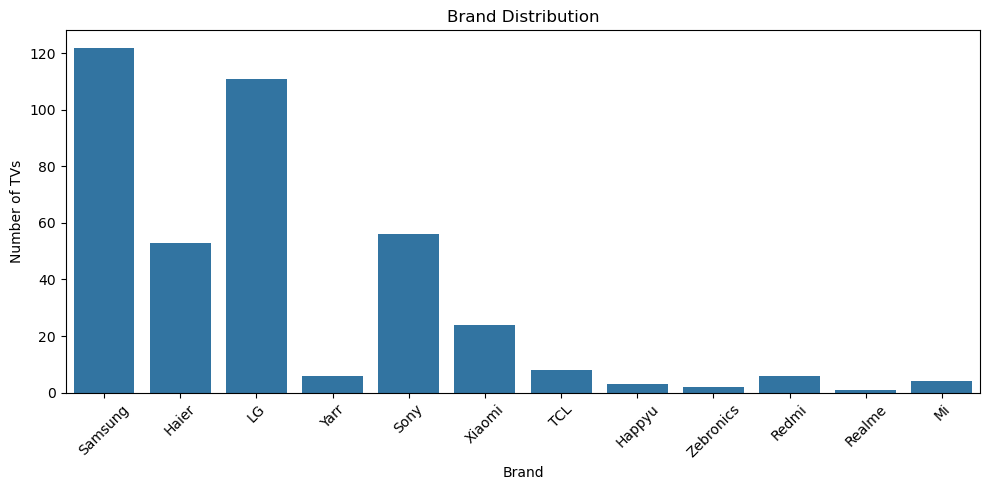

In [9]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Brand")

plt.title("Brand Distribution")
plt.xlabel("Brand")
plt.ylabel("Number of TVs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Screensize and price

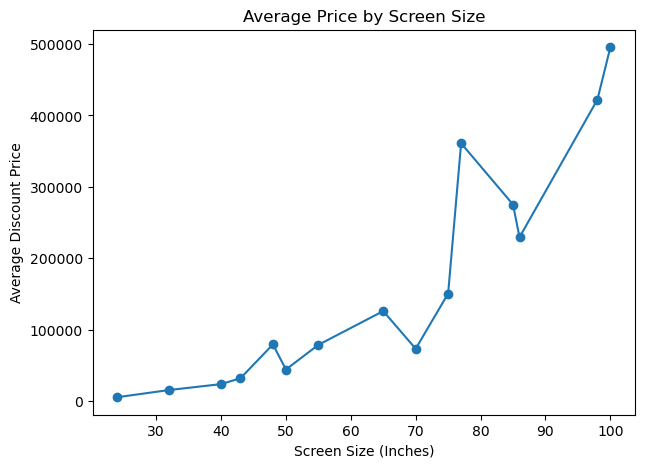

In [15]:
# How does the average TV price change with screen size?
avg_price = df.groupby("Inches")["Discount Price"].mean()

plt.figure(figsize=(7,5))
plt.plot(avg_price.index, avg_price.values, marker="o")

plt.title("Average Price by Screen Size")
plt.xlabel("Screen Size (Inches)")
plt.ylabel("Average Discount Price")
plt.show()
# In general, larger screen sizes tend to have higher average prices, although the price may vary between sizes.

### Price Distribution

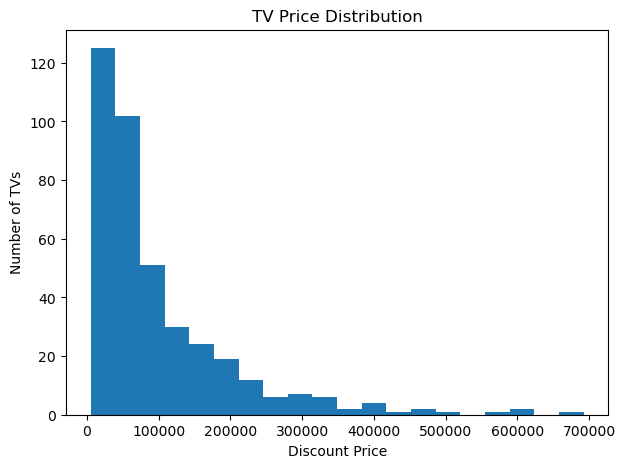

In [16]:
# How are TV prices distributed in the dataset?
plt.figure(figsize=(7,5))

plt.hist(df["Discount Price"], bins=20)

plt.title("TV Price Distribution")
plt.xlabel("Discount Price")
plt.ylabel("Number of TVs")
plt.show()
# Most TVs are concentrated in certain price ranges, while relatively fewer TVs are found at very high prices.

### Price Density

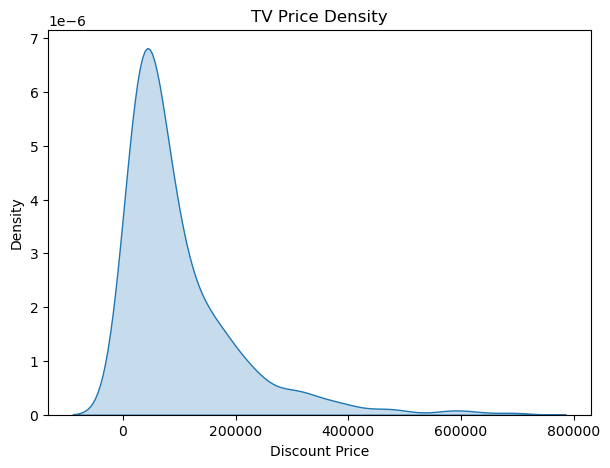

In [17]:
# Which price ranges have the highest concentration of TVs?
import seaborn as sns

plt.figure(figsize=(7,5))

sns.kdeplot(df["Discount Price"], fill=True)

plt.title("TV Price Density")
plt.xlabel("Discount Price")
plt.ylabel("Density")
plt.show()
# The highest peak represents the price range where TV listings are most concentrated.

### – Price Outliers

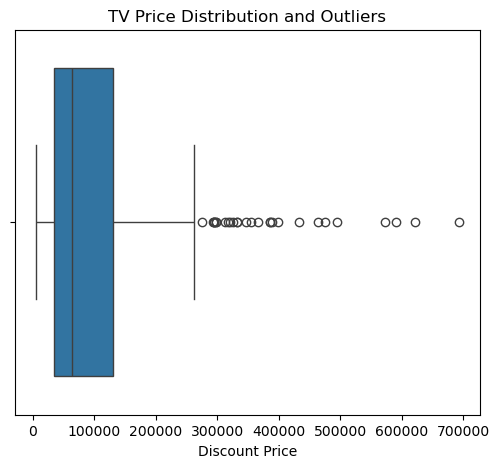

In [18]:
# Are there any unusually expensive or low-priced TVs?
plt.figure(figsize=(6,5))

sns.boxplot(x=df["Discount Price"])

plt.title("TV Price Distribution and Outliers")
plt.xlabel("Discount Price")
plt.show()
# TVs appearing outside the normal price range can be considered unusually expensive or inexpensive compared with most listings.

### Correlation Analysis

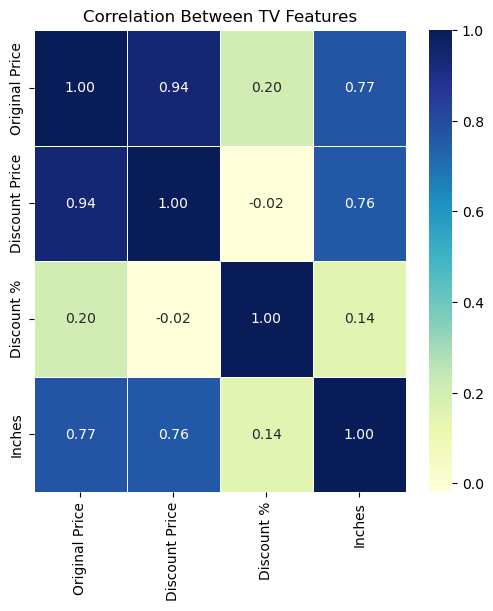

In [19]:
# How are price, discount, and screen size related to each other?
plt.figure(figsize=(6,6))

corr = df[
    ["Original Price", "Discount Price", "Discount %", "Inches"]
].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white"
)

plt.title("Correlation Between TV Features")
plt.show()
# Values closer to +1 indicate a strong positive relationship, values closer to -1 indicate a negative relationship, and values near 0 indicate a weak relationship.

## Hypothesis Testing

In [6]:
import numpy as np
import scipy.stats as st
import pandas as pd

In [7]:
def two_tail_t_test(population_mean, sample_size,
                    sample_mean, sample_std, cl):

    alpha = 1 - cl
    area = 1 - alpha / 2

    t_critical = st.t.ppf(area, df=sample_size - 1)

    t_stats = (sample_mean - population_mean) / (
        sample_std / (sample_size ** 0.5)
    )

    print("T-critical value:", t_critical)
    print("T-statistic:", t_stats)

    if np.abs(t_stats) > t_critical:
        print("Reject the null hypothesis")
    else:
        print("Fail to reject the null hypothesis")


samsung = pd.to_numeric(
    df.loc[
        df["Brand"].str.contains("Samsung", case=False, na=False),
        "Discount Price"
    ].astype(str).str.replace(r"[₹,\s]", "", regex=True),
    errors="coerce"
).dropna()

two_tail_t_test(
    population_mean=10000,
    sample_size=len(samsung),
    sample_mean=samsung.mean(),
    sample_std=samsung.std(),
    cl=0.95
)

T-critical value: 1.9797637624769302
T-statistic: 10.425284093243492
Reject the null hypothesis


In [4]:
df

,TV Name,Original Price,Discount Price,Discount %,Brand,Inches,Product URL
0,"Samsung 4K Ultra HD Neo QLED Smart TV QN80H, Q...","₹ 2,19,900","₹ 1,92,990",12%,Samsung,75,https://www.poorvika.com/samsung-4k-ultra-hd-n...
1,"Haier 4K Ultra HD Mini LED AI Smart Google TV,...","₹ 89,990","₹ 58,490",35%,Haier,55,https://www.poorvika.com/haier-4k-ultra-hd-min...
2,"LG Full HD Smart LED TV LB65 2026, 43LB6500PLB","₹ 37,990","₹ 29,990",21%,LG,43,https://www.poorvika.com/lg-full-hd-smart-led-...
3,Samsung 4K Ultra HD Micro RGB Smart TV 2026 R8...,"₹ 7,49,900","₹ 5,89,990",21%,Samsung,100,https://www.poorvika.com/samsung-4k-ultra-hd-m...
4,"Samsung Crystal 4K Ultra HD LED Smart TV 2026,...","₹ 5,19,900","₹ 4,32,990",17%,Samsung,98,https://www.poorvika.com/samsung-crystal-4k-ul...
...,...,...,...,...,...,...,...
391,TCL HD Ready LED Smart TV S65A,"₹ 29,990","₹ 16,990",43%,TCL,32,https://www.poorvika.com/tcl-hd-ready-led-smar...
392,Redmi HD Ready Smart TV,"₹ 24,999","₹ 13,999",44%,Redmi,32,https://www.poorvika.com/redmi-hd-ready-smart-...
393,Redmi 4K Ultra HD X Series Smart LED TV,"₹ 44,999","₹ 29,400",35%,Redmi,50,https://www.poorvika.com/redmi-4k-ultra-hd-x-s...
394,Mi 4K Ultra HD Tv 5X,"₹ 49,999","₹ 31,999",36%,Mi,43,https://www.poorvika.com/mi-4k-ultra-hd-tv-5x-...


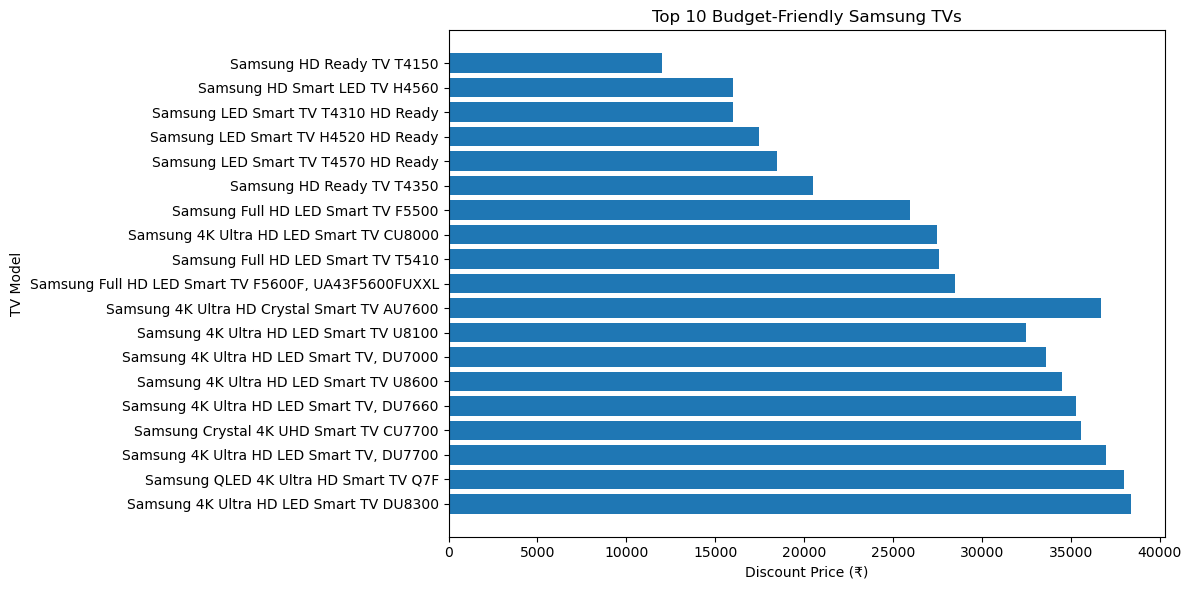

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

# Samsung TVs only
samsung = df[
    df["Brand"].str.contains("Samsung", case=False, na=False)
].copy()

# Convert Discount Price to numeric
samsung["Discount Price"] = pd.to_numeric(
    samsung["Discount Price"]
    .astype(str)
    .str.replace(r"[₹,\s]", "", regex=True),
    errors="coerce"
)

samsung = samsung.dropna(subset=["Discount Price"])

# Select 10 lowest-priced Samsung TVs
best_tvs = samsung.nsmallest(20, "Discount Price")

# Create chart
plt.figure(figsize=(12, 6))

plt.barh(
    best_tvs["TV Name"],
    best_tvs["Discount Price"]
)

plt.xlabel("Discount Price (₹)")
plt.ylabel("TV Model")
plt.title("Top 10 Budget-Friendly Samsung TVs")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()